# 06 · Explain and Ship: Grad-CAM, ONNX, INT8
**Builds on Modules 3 and 5; a preview of Module 7 (efficient edge AI)**

**Strategy:** a model is only useful if (1) we can check *why* it decides, and (2) it runs where farmers are: on a phone, offline.
1. **Grad-CAM:** does the model look at the lesions, or at the background?
2. **ONNX export:** one model file that runs anywhere (Streamlit, a browser, Android).
3. **Smaller models:** FP16 (half precision) and INT8 quantization. Does field accuracy survive?

In [1]:
import json, time, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from lab_to_field.config import CLASSES, N_CLASSES, FIGURES_DIR, CHECKPOINT_DIR, RESULTS_DIR, EXPORT_DIR, IMAGENET_MEAN, IMAGENET_STD
from lab_to_field.models import build_model
from lab_to_field.data import build_transforms, make_loader
from lab_to_field.experiment import splits
from lab_to_field.calibrate import softmax
plt.rcParams["figure.dpi"] = 110
S = splits(); eval_tf = build_transforms("none", train=False)
calib = json.loads((RESULTS_DIR / "calibration.json").read_text())

def load(name):
    m = build_model("mobilenetv3_large_100", N_CLASSES, pretrained=False)
    m.load_state_dict(torch.load(CHECKPOINT_DIR / f"{name}.pt")); return m.eval()

lab_model, final_model = load("03_mnv3_finetune"), load("05_final_field")

## 1. Grad-CAM: where is the model looking?

**How Grad-CAM works:**
1. Run the image forward and take the score of the predicted class.
2. Back-propagate that score to the **last convolutional feature maps** (7×7 here).
3. Average the gradients of each channel: this says how important that channel is for the decision.
4. Weighted sum of the feature maps → ReLU → upsample to the image size → a heatmap.

Red = regions that pushed the prediction up. If the heat sits on the background or the image border, the model is using a shortcut.

Below: the **lab-only** model (notebook 03, basic augmentation) vs the **final** model, on the same field photos.

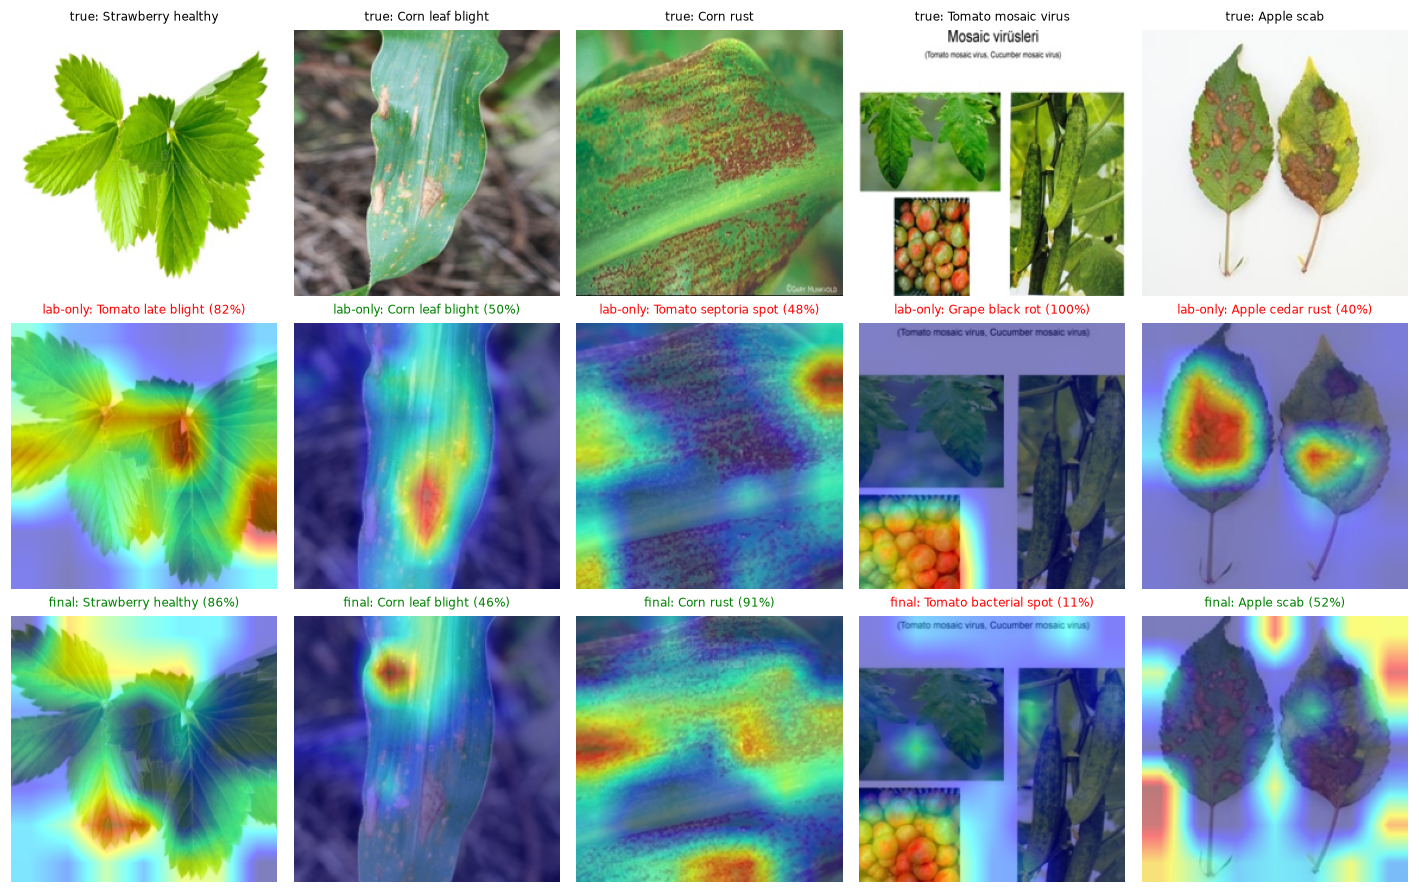

In [2]:
def cam_image(model, path):
    img = Image.open(path).convert("RGB")
    x = eval_tf(img)[None]
    rgb = (x[0].permute(1, 2, 0).numpy() * IMAGENET_STD + IMAGENET_MEAN).clip(0, 1).astype(np.float32)
    with GradCAM(model=model, target_layers=[model.blocks[-1]]) as cam:
        heat = cam(input_tensor=x, targets=None)[0]  # None = explain the predicted class
    with torch.no_grad():
        pred = model(x).softmax(1)[0]
    return show_cam_on_image(rgb, heat, use_rgb=True), CLASSES[int(pred.argmax())], float(pred.max())

paths = S["field_test"].sample(5, random_state=7)
fig, axes = plt.subplots(3, 5, figsize=(13, 8.2))
for c, (p, y) in enumerate(zip(paths.path, paths.label)):
    axes[0, c].imshow(Image.open(p).convert("RGB").resize((224, 224))); axes[0, c].set_title(f"true: {CLASSES[y]}", fontsize=8)
    for r, (m, tag) in enumerate([(lab_model, "lab-only"), (final_model, "final")], start=1):
        im, pred, conf = cam_image(m, p)
        axes[r, c].imshow(im); axes[r, c].set_title(f"{tag}: {pred} ({conf:.0%})", fontsize=8,
                                                     color="green" if pred == CLASSES[y] else "red")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "06_gradcam.png", bbox_inches="tight")

**Interpretation:** compare rows 2 and 3. Correct predictions should come with heat on the diseased spots. Wrong predictions often show heat on background, soil or another leaf, which is direct evidence of the shortcut problem from notebook 01.

## 2. Export to ONNX
**ONNX** (Open Neural Network Exchange) is a standard file format for trained networks. After export the app does not need PyTorch:
the same `.onnx` file runs with ONNX Runtime in Python (Streamlit), in a browser (onnxruntime-web) and on Android.

In [3]:
import warnings, onnx, onnxruntime as ort
warnings.filterwarnings("ignore", category=DeprecationWarning)  # we use the classic exporter on purpose: simple and stable
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
fp32_path = EXPORT_DIR / "plant_fp32.onnx"
torch.onnx.export(final_model.cpu(), torch.randn(1, 3, 224, 224), fp32_path, input_names=["image"], output_names=["logits"],
                  dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17, dynamo=False)
onnx.checker.check_model(onnx.load(fp32_path))

# Parity check: ONNX must give the same answer as PyTorch
x = torch.randn(4, 3, 224, 224)
sess = ort.InferenceSession(fp32_path, providers=["CPUExecutionProvider"])
diff = np.abs(sess.run(None, {"image": x.numpy()})[0] - final_model(x).detach().numpy()).max()
print(f"max difference PyTorch vs ONNX: {diff:.2e}  (tiny = correct export)")
(EXPORT_DIR / "labels.json").write_text(json.dumps(calib, indent=2))

# FP16: store every weight as a 16-bit float. Half the size; inputs/outputs stay float32 for the app.
from onnxruntime.transformers.float16 import convert_float_to_float16
fp16_path = EXPORT_DIR / "plant_fp16.onnx"
onnx.save(convert_float_to_float16(onnx.load(fp32_path), keep_io_types=True), fp16_path)

max difference PyTorch vs ONNX: 2.89e-06  (tiny = correct export)


## 3. INT8 quantization
Weights and activations are stored as 8-bit integers instead of 32-bit floats: **4× less memory** and faster integer maths on phone CPUs.

**Static post-training quantization:**
1. Run ~300 *calibration* images through the model and record the range (min/max) of every activation.
2. Map each range onto the 256 integer levels: `x_int8 = round(x / scale) + zero_point`.
3. Weights are quantized **per channel** (each filter gets its own scale), which keeps more accuracy.
4. Activations use unsigned 8-bit (0–255) with a zero point; in our tests this lost less accuracy than signed 8-bit.

Calibration images come from the training/validation pools (lab val + PlantDoc val), never from the test set.

In [4]:
from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantFormat, QuantType
from onnxruntime.quantization.shape_inference import quant_pre_process

class Reader(CalibrationDataReader):
    def __init__(self, df):
        self.it = iter([{"image": eval_tf(Image.open(p).convert("RGB"))[None].numpy()} for p in df.path])
    def get_next(self):
        return next(self.it, None)

prep_path, int8_path = EXPORT_DIR / "plant_prep.onnx", EXPORT_DIR / "plant_int8.onnx"
quant_pre_process(str(fp32_path), str(prep_path))
calib_df = pd.concat([S["lab_val"].sample(150, random_state=0), S["field_val"].sample(150, random_state=0)])
quantize_static(str(prep_path), str(int8_path), Reader(calib_df), quant_format=QuantFormat.QDQ,
                per_channel=True, activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8)
prep_path.unlink()

In [5]:
def evaluate(path, df, threads=4):
    so = ort.SessionOptions(); so.intra_op_num_threads = threads
    s = ort.InferenceSession(str(path), so, providers=["CPUExecutionProvider"])
    logits = np.concatenate([s.run(None, {"image": eval_tf(Image.open(p).convert("RGB"))[None].numpy()})[0] for p in df.path])
    x = eval_tf(Image.open(df.path.iloc[0]).convert("RGB"))[None].numpy()
    for _ in range(5): s.run(None, {"image": x})
    t = time.perf_counter()
    for _ in range(30): s.run(None, {"image": x})
    return logits, (time.perf_counter() - t) / 30 * 1000

rows = []
for tag, path in [("FP32", fp32_path), ("FP16", fp16_path), ("INT8", int8_path)]:
    lg, ms = evaluate(path, S["field_test"])
    pr = softmax(lg, calib["temperature"])
    rows.append({"model": tag, "size (MB)": path.stat().st_size / 1e6, "CPU ms / image": ms,
                 "field acc": (pr.argmax(1) == S["field_test"].label.values).mean()})
q = pd.DataFrame(rows); q["field acc change (pts)"] = (q["field acc"] - q["field acc"].iloc[0]) * 100
q.round(3)

,model,size (MB),CPU ms / image,field acc,field acc change (pts)
0,FP32,16.939,2.892,0.644,0.000
1,FP16,8.499,3.289,0.644,0.000
2,INT8,4.729,3.135,0.606,-3.814


**Read it:**
- **FP16** halves the size with **no** accuracy loss: this is what the app ships by default.
- **INT8** is ~3.6× smaller but loses a few field points and, on this laptop's x86 CPU, is not faster (integer kernels pay off mainly on phone ARM CPUs).
  MobileNetV3 is known to be hard to quantize: its hard-swish activations and squeeze-and-excitation blocks produce value ranges that 8 bits represent poorly.
  Published numbers show the same pattern (MobileNetV2: 71.9% → 63.7% with post-training INT8 in TensorFlow's reference table).
- **Decision:** ship FP16 now; fix INT8 with **quantization-aware training** (train while simulating 8-bit rounding), which is Module 7 and the plan for Group Project 2.

### Our results
| Format | Size | Field acc | CPU ms / image (laptop) |
|---|---|---|---|
| FP32 | 16.9 MB | 64.4% | ~3 |
| **FP16 (shipped)** | **8.5 MB** | **64.4%** | ~3 |
| INT8 (static, per-channel) | 4.7 MB | ~60.6% | ~3.4 |

**Grad-CAM on 5 random field test photos** (figure above): the lab-only model gets 1 of 5 right, the final model 4 of 5.
- *Corn rust:* lab-only looks at an image corner and says "Tomato septoria spot"; the final model looks across the rust pustules (91%, correct).
- *Strawberry healthy:* lab-only says "Tomato late blight" at 82% confidence, a confident mistake; the final model is correct.
- *Tomato mosaic virus:* this PlantDoc "photo" is a web collage with text (label noise in the dataset). The final model gives only **11%** confidence, so the app would say "not sure". That is the abstention working as designed.
- *Apple scab:* the final model is correct, but part of its heat sits on the white border: it still uses some background cues. Grad-CAM shows the fix is partial, not complete, and that is worth saying.

- ONNX export matches PyTorch to ~2e-6: a correct export.
- FP16 halves the size for free. INT8 costs ~4 points on MobileNetV3, so it needs quantization-aware training (Module 7) before we ship it.

## Review questions
1. Explain Grad-CAM in four steps. Why use the *last* convolutional layer?
2. What would a Grad-CAM heatmap on the background tell you?
3. What is ONNX and why export to it? How did we check the export is correct?
4. How does INT8 quantization reduce size by 4×? What are `scale` and `zero_point`? Why did we ship FP16 instead?
5. Why must calibration images not come from the test set?
6. Per-channel vs per-tensor quantization: which keeps more accuracy and why?